In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

sys.path.insert(0, "../src")   # shared grid + map helpers live in src/grid.py
from grid import (LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, RES, lon_edges, lat_edges,
                  lon_c, lat_c, proj, style_map)
from grid import nx as NX, ny as NY

In [2]:
DATA_DIR = Path("../data")      # data, tables, results (parquet, npz, csv, json)
FIG_DIR  = Path("../figures")   # all figures (png)

# Each notebook writes to its own subfolder; inputs come from earlier notebooks' folders
OUT_DIR = DATA_DIR / "04_bootstrap"
FIG_OUT = FIG_DIR / "04_bootstrap"
DIR_03  = DATA_DIR / "03_aggregation_and_means"       # agg_vel / agg_sst, weighting_diff
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# --- Bootstrap settings ---
B = 3000                  # bootstrap replicates per grid cell
SEED = 20261105           # fixed seed for reproducibility
# Display mask (>= 10 drifters) for a quick look only; not part of the method.
# The report versions of these maps, with reliability (N* and U95) marked,
# are drawn in 08_maps_with_reliability.
MIN_N_PLOT = 10           # display only: cells with fewer drifters are marked ×
TARGET_CMPS = 10.0        # precision target (cm/s), as in the Method
SST_TARGET_C = 0.5        # SST precision target (°C), as in the reliability step
BANDS = [2, 5, 10, 20, np.inf]                       # drifter-count bands for the summary
BAND_LABELS = ['2-4', '5-9', '10-19', '20+']

agg_vel = pd.read_parquet(DIR_03 / "agg_vel_1deg.parquet")
print(f"Velocity aggregate: {len(agg_vel):,} rows")
print(agg_vel.head().to_string(index=False))

Velocity aggregate: 23,722 rows
 iy  ix              id    enso   n    sum_ve    sum_vn
  0   0           49632 Neutral  70 -1.539700  1.969500
  0   0          139801 El Niño 119 29.830900 -6.839100
  0   0          139804 El Niño 147 29.963699 12.354700
  0   0 300234060291780 Neutral  74 14.902200 30.791599
  0   0 300234060999470 Neutral  76 -6.300600 32.247200


In [4]:
# --- Check the aggregate table before using it ---
keys = ['iy', 'ix', 'id']
required = keys + ['n', 'sum_ve', 'sum_vn']

assert set(required).issubset(agg_vel.columns), 'Missing columns: is this the velocity aggregate file?'
assert agg_vel[required].notna().all().all(), 'Aggregate table has missing values.'
assert np.isfinite(agg_vel[['n', 'sum_ve', 'sum_vn']].to_numpy()).all(), 'Non-finite values found.'
assert (agg_vel['n'] > 0).all(), 'Every row should have at least one hour.'
assert (agg_vel['n'] % 1 == 0).all(), 'Hour counts should be whole numbers.'
assert agg_vel['iy'].between(0, NY - 1).all() and agg_vel['ix'].between(0, NX - 1).all(), \
    'Cell indices fall outside the grid.'

# --- Combine ENSO phases: one row per (grid cell, drifter) ---
# The bootstrap resamples whole drifters, so each drifter must be a single row per cell
vel = (agg_vel.astype({'sum_ve': 'float64', 'sum_vn': 'float64'})
       .groupby(keys, as_index=False, sort=True)[['n', 'sum_ve', 'sum_vn']].sum())

assert not vel.duplicated(keys).any(), 'Each (cell, drifter) should appear once.'
assert int(vel['n'].sum()) == int(agg_vel['n'].sum()), 'Combining phases should not change total hours.'

print(f"After combining ENSO rows: {len(vel):,} cell–drifter records")
print(f"Grid cells with velocity data: {vel.groupby(['iy', 'ix']).ngroups}")
print(f"Total drogued hours: {vel['n'].sum():,}")

After combining ENSO rows: 22,932 cell–drifter records
Grid cells with velocity data: 595
Total drogued hours: 2,135,791


In [5]:
def bootstrap_means(sums, hours, B, rng, batch=250):
    """
    Whole-drifter bootstrap of an hour-weighted mean.
    Each replicate draws N drifters with replacement (N = drifters in the cell)
    and recomputes mean = sum of their sums / sum of their hours.
    Replicates are processed in batches to limit memory use.
    """
    sums = np.asarray(sums, dtype=np.float64)
    if sums.ndim == 1:
        sums = sums[:, None]                         # allow one variable (e.g. SST) or several
    hours = np.asarray(hours, dtype=np.float64)
    N = len(hours)
    assert N >= 2 and len(sums) == N and (hours > 0).all()
    draws = np.empty((B, sums.shape[1]), dtype=np.float64)
    for start in range(0, B, batch):
        stop = min(start + batch, B)
        ids = rng.integers(0, N, size=(stop - start, N))     # draw N drifters with replacement
        draws[start:stop] = sums[ids].sum(axis=1) / hours[ids].sum(axis=1)[:, None]
    return draws

def velocity_ci(sums, hours, mean, rng):
    """95% percentile CIs, bootstrap SEs and U95 (all cm/s) for one cell's mean current."""
    draws = bootstrap_means(sums, hours, B, rng) * 100              # m/s → cm/s
    lo, hi = np.quantile(draws, [0.025, 0.975], axis=0)             # 95% percentile CI
    se = draws.std(axis=0, ddof=1)                                  # bootstrap standard error
    out = {}
    for j, component in enumerate(['ve', 'vn']):
        out[f'{component}_ci_low_cmps'] = float(lo[j])
        out[f'{component}_ci_high_cmps'] = float(hi[j])
        out[f'{component}_ci_halfwidth_cmps'] = float((hi[j] - lo[j]) / 2)
        out[f'{component}_bootstrap_se_cmps'] = float(se[j])
    # U95: 95th percentile of the distance between each replicate's mean vector and the cell mean
    distance = np.linalg.norm(draws - mean[None, :] * 100, axis=1)
    out['bootstrap_vector_radius95_cmps'] = float(np.quantile(distance, 0.95))
    return out


def cell_rng(seed, iy, ix, stream):
    """Separate, reproducible random stream for each cell (stream 1 = velocity, 2 = SST)."""
    return np.random.default_rng(np.random.SeedSequence([seed, int(iy), int(ix), stream]))


def to_grid(column, table):
    """Column of a per-cell table → 2-D map (lat x lon); cells with < MIN_N_PLOT drifters hidden."""
    a = table[column].to_numpy(dtype=float, copy=True).reshape(NY, NX)
    a[(table['n_drifters'] < MIN_N_PLOT).to_numpy().reshape(NY, NX)] = np.nan
    return a


def draw_map(ax, column, title, table, vmin=0, vmax=None, cmap='YlOrRd', mark_few=True):
    """Shaded map (cells with < MIN_N_PLOT drifters hidden); × marks those cells."""
    m = ax.pcolormesh(lon_edges, lat_edges, to_grid(column, table), cmap=cmap,
                      vmin=vmin, vmax=vmax, transform=proj)
    if mark_few:
        few = table[table['small_n_flag']]
        ax.scatter(few['lon_center'], few['lat_center'], marker='x', s=12, c='grey', transform=proj)
    style_map(ax, title)
    return m

In [6]:
rows = []
for (iy, ix), g in vel.groupby(['iy', 'ix'], sort=True):
    sums = g[['sum_ve', 'sum_vn']].to_numpy(dtype=np.float64)
    hours = g['n'].to_numpy(dtype=np.float64)
    N = len(g)                                              # distinct drifters in the cell
    mean = sums.sum(axis=0) / hours.sum()                   # full-data mean (m/s)

    row = dict(iy=int(iy), ix=int(ix), n_drifters=N, n_hours=int(hours.sum()),
               mean_ve_cmps=float(mean[0] * 100), mean_vn_cmps=float(mean[1] * 100),
               mean_vector_speed_cmps=float(np.hypot(*mean) * 100),
               max_drifter_hour_share=float(hours.max() / hours.sum()))   # largest single drifter's share

    fields = ['ve_ci_low_cmps', 've_ci_high_cmps', 've_ci_halfwidth_cmps',
              'vn_ci_low_cmps', 'vn_ci_high_cmps', 'vn_ci_halfwidth_cmps',
              've_bootstrap_se_cmps', 'vn_bootstrap_se_cmps',
              'bootstrap_vector_radius95_cmps']
    row.update({name: np.nan for name in fields})           # stays NaN if the cell has 1 drifter

    if N >= 2:
        row.update(velocity_ci(sums, hours, mean, cell_rng(SEED, iy, ix, 1)))
    rows.append(row)

print(f"Bootstrapped {len(rows)} grid cells with velocity data.")

Bootstrapped 595 grid cells with velocity data.


In [7]:
# --- Full 25 × 30 grid; cells with no data keep NaN ---
full_index = pd.MultiIndex.from_product([range(NY), range(NX)], names=['iy', 'ix'])
result = pd.DataFrame(rows).set_index(['iy', 'ix']).reindex(full_index).reset_index()
for name in ['n_drifters', 'n_hours']:
    result[name] = result[name].fillna(0).astype('int64')

result['lon_center'] = lon_c[result['ix']]
result['lat_center'] = lat_c[result['iy']]
result['ci_estimable'] = result['n_drifters'] >= 2
result['small_n_flag'] = (result['n_drifters'] > 0) & (result['n_drifters'] < MIN_N_PLOT)
result['n_bootstrap'] = np.where(result['ci_estimable'], B, 0)

# Mean speed relative to its uncertainty: > 1 means the mean current's direction is resolved
result['snr'] = result['mean_vector_speed_cmps'] / result['bootstrap_vector_radius95_cmps']

# --- Weighting sensitivity (Method 4.3): per-drifter vs per-hour mean, against U95 ---
weighting_diff = np.load(DIR_03 / "weighting_diff_1deg.npy")          # m/s, shape (NY, NX)
assert weighting_diff.shape == (NY, NX)
result['weighting_diff_cmps'] = weighting_diff[result['iy'], result['ix']] * 100
result['weighting_sensitive'] = pd.Series(
    result['weighting_diff_cmps'] > result['bootstrap_vector_radius95_cmps'], dtype='boolean'
).where(result['ci_estimable'])                                       # <NA> where no interval
assert result.loc[result['ci_estimable'], 'weighting_diff_cmps'].notna().all()

result.to_parquet(OUT_DIR / "bootstrap_velocity_1deg.parquet", index=False)
result.to_csv(OUT_DIR / "bootstrap_velocity_1deg.csv", index=False)

print(f"Done: {len(result):,} grid cells; {(result.n_drifters > 0).sum()} with velocity data.")
print(f"CI computable (≥2 drifters): {result.ci_estimable.sum()} cells.")
print(f"Few-drifter cells (1–9): {result.small_n_flag.sum()} cells.")

Done: 750 grid cells; 595 with velocity data.
CI computable (≥2 drifters): 577 cells.
Few-drifter cells (1–9): 59 cells.


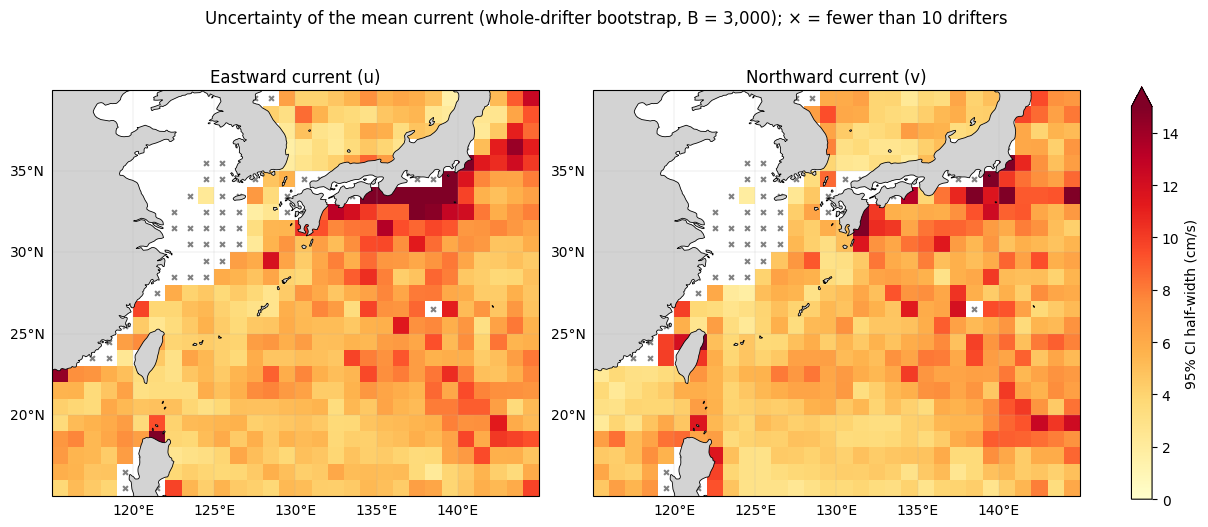

In [8]:
n_ge_10 = result['n_drifters'] >= MIN_N_PLOT        # cells shown on the maps (display only)

# --- Figure: 95% CI half-width of each velocity component ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout='constrained',
                         subplot_kw={'projection': proj})
for ax, comp, title in zip(axes, ['ve', 'vn'], ['Eastward current (u)', 'Northward current (v)']):
    m = draw_map(ax, f'{comp}_ci_halfwidth_cmps', title, result, vmax=15)

fig.colorbar(m, ax=axes, shrink=0.8, extend='max', label='95% CI half-width (cm/s)')
fig.suptitle(f'Uncertainty of the mean current (whole-drifter bootstrap, B = {B:,}); '
             f'× = fewer than {MIN_N_PLOT} drifters')
fig.savefig(FIG_OUT / 'bootstrap_ci_halfwidth_map_initial.png', dpi=300, bbox_inches='tight')
plt.show()

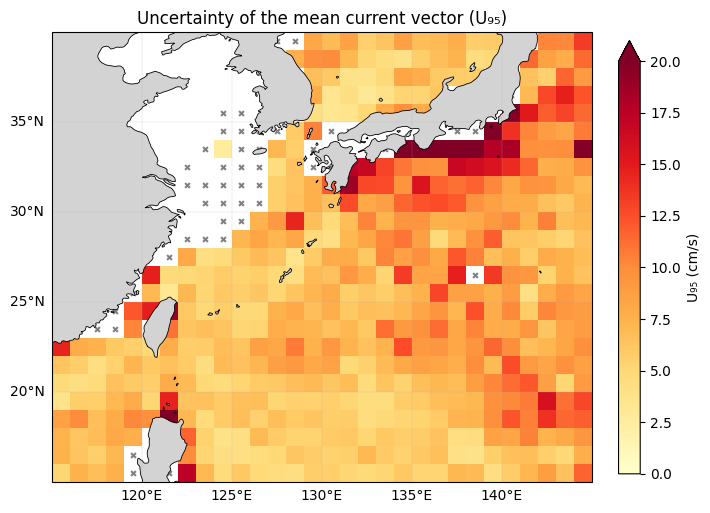

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.5), layout='constrained', subplot_kw={'projection': proj})
m = draw_map(ax, 'bootstrap_vector_radius95_cmps', 'Uncertainty of the mean current vector (U₉₅)', result, vmax=20)
fig.colorbar(m, ax=ax, shrink=0.8, extend='max', label='U₉₅ (cm/s)')
fig.savefig(FIG_OUT / 'bootstrap_U95_map_initial.png', dpi=300, bbox_inches='tight')
plt.show()

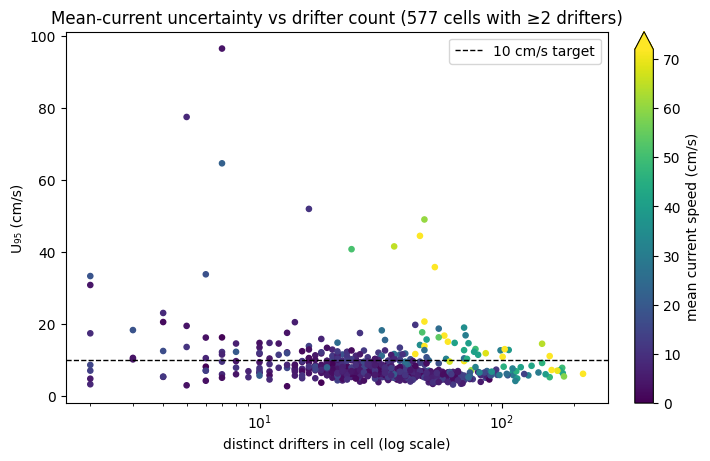

In [10]:
# --- U95 against drifter count, for every cell with an interval ---
ci = result['ci_estimable']
fig, ax = plt.subplots(figsize=(7, 4.5), layout='constrained')
sc = ax.scatter(result.loc[ci, 'n_drifters'], result.loc[ci, 'bootstrap_vector_radius95_cmps'],
                c=result.loc[ci, 'mean_vector_speed_cmps'], cmap='viridis', s=14,
                norm=Normalize(vmin=0, vmax=np.nanpercentile(result.loc[ci, 'mean_vector_speed_cmps'], 98)))
ax.axhline(TARGET_CMPS, color='k', ls='--', lw=1, label=f'{TARGET_CMPS:.0f} cm/s target')
ax.set_xscale('log')
ax.set(xlabel='distinct drifters in cell (log scale)', ylabel='U₉₅ (cm/s)',
       title=f'Mean-current uncertainty vs drifter count ({ci.sum()} cells with ≥2 drifters)')
fig.colorbar(sc, ax=ax, extend='max', label='mean current speed (cm/s)')
ax.legend(loc='upper right')
fig.savefig(FIG_OUT / 'U95_vs_ndrifters.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
# --- Summary numbers for the report ---
within_target = n_ge_10 & (result['bootstrap_vector_radius95_cmps'] <= TARGET_CMPS)

summary = {
    "bootstrap_repetitions": B,
    "seed": SEED,
    "target_cmps": TARGET_CMPS,
    "cells_with_velocity_data": int((result['n_drifters'] > 0).sum()),
    "cells_ci_estimable_n_ge_2": int(result['ci_estimable'].sum()),
    "cells_n_ge_10": int(n_ge_10.sum()),
    "cells_n_ge_10_U95_within_target": int(within_target.sum()),
    "median_ve_ci_halfwidth_cmps_n_ge_10": float(result.loc[n_ge_10, 've_ci_halfwidth_cmps'].median()),
    "median_vn_ci_halfwidth_cmps_n_ge_10": float(result.loc[n_ge_10, 'vn_ci_halfwidth_cmps'].median()),
    "median_U95_cmps_n_ge_10": float(result.loc[n_ge_10, 'bootstrap_vector_radius95_cmps'].median()),
    "share_n_ge_10_snr_gt_1": float((result.loc[n_ge_10, 'snr'] > 1).mean()),
}


def q(x, p):
    return round(float(np.nanquantile(x, p)), 4)

def vel_stats(t):
    """Velocity uncertainty summary over the rows of t (cells with an interval)."""
    u = t['bootstrap_vector_radius95_cmps']
    return {"n_cells": int(len(t)),
            "median_U95_cmps": q(u, 0.5), "iqr_U95_cmps": [q(u, 0.25), q(u, 0.75)],
            "median_ve_ci_halfwidth_cmps": q(t['ve_ci_halfwidth_cmps'], 0.5),
            "median_vn_ci_halfwidth_cmps": q(t['vn_ci_halfwidth_cmps'], 0.5),
            "share_U95_le_target": round(float((u <= TARGET_CMPS).mean()), 4),
            "share_snr_gt_1": round(float((t['snr'] > 1).mean()), 4)}

def by_band(t, stats):
    band = pd.cut(t['n_drifters'], BANDS, right=False, labels=BAND_LABELS)
    return {str(b): stats(g) for b, g in t.groupby(band, observed=False)}

with_ci = result[result['ci_estimable']]
summary["velocity_all_ci_cells"] = vel_stats(with_ci)
summary["velocity_by_drifter_band"] = by_band(with_ci, vel_stats)

# Weighting sensitivity: does the per-drifter vs per-hour difference exceed U95?
ws = result['weighting_sensitive']
ge5 = result['ci_estimable'] & (result['n_drifters'] >= 5)
summary["weighting_sensitive"] = {
    "all_ci_cells": {"n_cells": int(ci.sum()), "n_sensitive": int(ws[ci].sum()),
                     "share": round(float(ws[ci].mean()), 4)},
    "n_ge_5":       {"n_cells": int(ge5.sum()), "n_sensitive": int(ws[ge5].sum()),
                     "share": round(float(ws[ge5].mean()), 4)},
}
print(json.dumps({k: summary[k] for k in ["velocity_all_ci_cells", "weighting_sensitive"]}, indent=2))
print(pd.DataFrame(summary["velocity_by_drifter_band"]).T.to_string())

{
  "velocity_all_ci_cells": {
    "n_cells": 577,
    "median_U95_cmps": 7.2271,
    "iqr_U95_cmps": [
      5.8291,
      9.5559
    ],
    "median_ve_ci_halfwidth_cmps": 5.4856,
    "median_vn_ci_halfwidth_cmps": 5.5023,
    "share_U95_le_target": 0.7816,
    "share_snr_gt_1": 0.5234
  },
  "weighting_sensitive": {
    "all_ci_cells": {
      "n_cells": 577,
      "n_sensitive": 221,
      "share": 0.383
    },
    "n_ge_5": {
      "n_cells": 562,
      "n_sensitive": 221,
      "share": 0.3932
    }
  }
}
      n_cells median_U95_cmps       iqr_U95_cmps median_ve_ci_halfwidth_cmps median_vn_ci_halfwidth_cmps share_U95_le_target share_snr_gt_1
2-4        15         10.5802  [6.2042, 19.4324]                      5.8654                      8.3169                 0.4         0.4667
5-9        26         10.0953     [6.91, 15.817]                      5.2927                      8.2342                 0.5         0.3462
10-19      90          8.0726  [7.1351, 10.3138]                

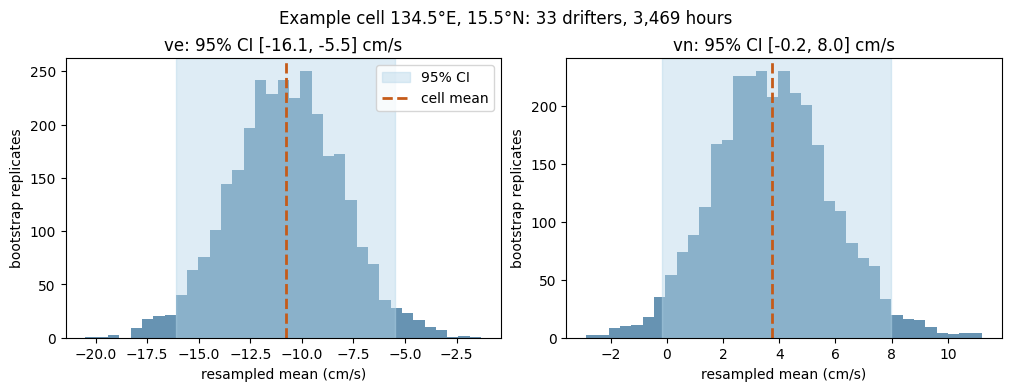

lon_center                            134.5
lat_center                             15.5
n_drifters                               33
n_hours                                3469
mean_ve_cmps                     -10.757021
ve_ci_low_cmps                   -16.098098
ve_ci_high_cmps                   -5.490499
mean_vn_cmps                        3.74143
vn_ci_low_cmps                     -0.15428
vn_ci_high_cmps                    7.969945
bootstrap_vector_radius95_cmps     6.097632
snr                                1.867792


In [12]:
# --- Pick a typical cell: the one whose drifter count is closest to the median ---
observed = result[n_ge_10]
example = observed.iloc[(observed['n_drifters'] - observed['n_drifters'].median()).abs().argmin()]

# --- Rerun its bootstrap with the same random stream as the main loop, so the numbers match ---
g = vel[(vel['iy'] == example['iy']) & (vel['ix'] == example['ix'])]
rng = cell_rng(SEED, example['iy'], example['ix'], 1)
draws = bootstrap_means(g[['sum_ve', 'sum_vn']].to_numpy(), g['n'].to_numpy(), B, rng) * 100   # cm/s

# --- Histogram of the resampled means for each component, with the 95% CI shaded ---
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
for j, (ax, comp) in enumerate(zip(axes, ['ve', 'vn'])):
    low, high = example[f'{comp}_ci_low_cmps'], example[f'{comp}_ci_high_cmps']
    ax.hist(draws[:, j], bins=35, color='#4c80a5', alpha=0.85)
    ax.axvspan(low, high, color='#b6d6e9', alpha=0.45, label='95% CI')
    ax.axvline(example[f'mean_{comp}_cmps'], color='#c55b19', ls='--', lw=2, label='cell mean')
    ax.set(title=f'{comp}: 95% CI [{low:.1f}, {high:.1f}] cm/s',
           xlabel='resampled mean (cm/s)', ylabel='bootstrap replicates')
axes[0].legend()

fig.suptitle(f'Example cell {example.lon_center:.1f}°E, {example.lat_center:.1f}°N: '
             f'{int(example.n_drifters)} drifters, {int(example.n_hours):,} hours')
fig.savefig(FIG_OUT / 'example_bootstrap.png', dpi=300, bbox_inches='tight')
plt.show()

print(example[['lon_center', 'lat_center', 'n_drifters', 'n_hours',
               'mean_ve_cmps', 've_ci_low_cmps', 've_ci_high_cmps',
               'mean_vn_cmps', 'vn_ci_low_cmps', 'vn_ci_high_cmps',
               'bootstrap_vector_radius95_cmps', 'snr']].to_string())

In [13]:
# --- Load and check the SST aggregate (all drifters, flag-5 SST only) ---
agg_sst = pd.read_parquet(DIR_03 / "agg_sst_1deg.parquet")
assert set(keys + ['n', 'sum_sst']).issubset(agg_sst.columns), 'Is this the SST aggregate file?'
assert agg_sst[keys + ['n', 'sum_sst']].notna().all().all(), 'SST aggregate has missing values.'
assert (agg_sst['n'] > 0).all()

# --- Combine ENSO phases: one row per (grid cell, drifter) ---
sst = (agg_sst.astype({'sum_sst': 'float64'})
       .groupby(keys, as_index=False, sort=True)[['n', 'sum_sst']].sum())

# --- Bootstrap each cell (same function as velocity; separate random stream via the trailing 2) ---
sst_rows = []
for (iy, ix), g in sst.groupby(['iy', 'ix'], sort=True):
    mean_c = float(g['sum_sst'].sum() / g['n'].sum() - 273.15)          # K → °C
    low = high = half = np.nan
    if len(g) >= 2:
        rng = cell_rng(SEED, iy, ix, 2)
        draws_c = bootstrap_means(g[['sum_sst']].to_numpy(), g['n'].to_numpy(), B, rng)[:, 0] - 273.15
        low, high = np.quantile(draws_c, [0.025, 0.975])
        half = (high - low) / 2
    sst_rows.append(dict(iy=int(iy), ix=int(ix), n_drifters=len(g), n_hours=int(g['n'].sum()),
                         mean_sst_c=mean_c, sst_ci_low_c=low, sst_ci_high_c=high,
                         sst_ci_halfwidth_c=half))

# --- Full grid table, flags, save ---
sst_result = pd.DataFrame(sst_rows).set_index(['iy', 'ix']).reindex(full_index).reset_index()
for name in ['n_drifters', 'n_hours']:
    sst_result[name] = sst_result[name].fillna(0).astype('int64')
sst_result['lon_center'] = lon_c[sst_result['ix']]
sst_result['lat_center'] = lat_c[sst_result['iy']]
sst_result['ci_estimable'] = sst_result['n_drifters'] >= 2
sst_result['small_n_flag'] = sst_result['n_drifters'].between(1, MIN_N_PLOT - 1)
sst_result['n_bootstrap'] = np.where(sst_result['ci_estimable'], B, 0)

sst_result.to_parquet(OUT_DIR / "bootstrap_sst_1deg.parquet", index=False)
sst_result.to_csv(OUT_DIR / "bootstrap_sst_1deg.csv", index=False)

sst_valid = sst_result['n_drifters'] >= MIN_N_PLOT
print(f"SST: {len(agg_sst):,} rows → {len(sst):,} cell–drifter records; "
      f"{(sst_result['n_drifters'] > 0).sum()} cells with data.")
print(f"Median SST CI half-width (≥10 drifters): "
      f"{sst_result.loc[sst_valid, 'sst_ci_halfwidth_c'].median():.2f} °C")

SST: 48,153 rows → 45,630 cell–drifter records; 618 cells with data.
Median SST CI half-width (≥10 drifters): 0.75 °C


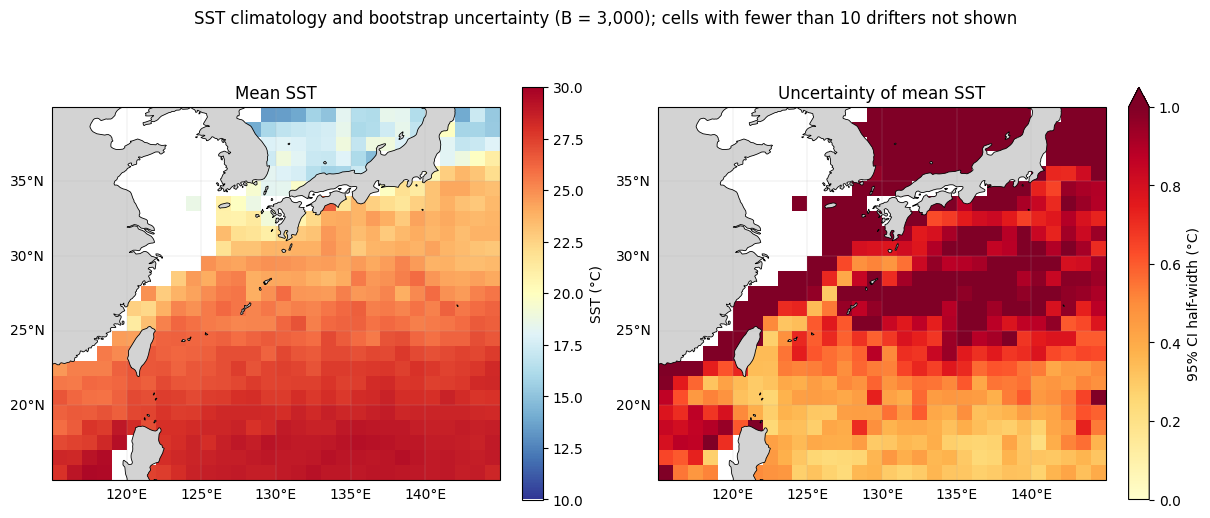

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout='constrained',
                         subplot_kw={'projection': proj})

m1 = draw_map(axes[0], 'mean_sst_c', 'Mean SST', sst_result, 10, 30, 'RdYlBu_r', mark_few=False)
fig.colorbar(m1, ax=axes[0], shrink=0.8, label='SST (°C)')

m2 = draw_map(axes[1], 'sst_ci_halfwidth_c', 'Uncertainty of mean SST', sst_result, 0, 1.0, 'YlOrRd',
              mark_few=False)
fig.colorbar(m2, ax=axes[1], shrink=0.8, extend='max', label='95% CI half-width (°C)')

fig.suptitle(f'SST climatology and bootstrap uncertainty (B = {B:,}); '
             f'cells with fewer than {MIN_N_PLOT} drifters not shown')
fig.savefig(FIG_OUT / 'bootstrap_sst_map_initial.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
# --- SST uncertainty summary ---
def sst_stats(t):
    h = t['sst_ci_halfwidth_c']
    return {"n_cells": int(len(t)),
            "median_halfwidth_c": q(h, 0.5), "iqr_halfwidth_c": [q(h, 0.25), q(h, 0.75)],
            "share_halfwidth_le_target": round(float((h <= SST_TARGET_C).mean()), 4)}

sst_ci = sst_result[sst_result['ci_estimable']]
summary["sst"] = {
    "target_c": SST_TARGET_C,
    "cells_with_data": int((sst_result['n_drifters'] > 0).sum()),
    "cells_ci_estimable_n_ge_2": int(len(sst_ci)),
    "all_ci_cells": sst_stats(sst_ci),
    "n_ge_10": sst_stats(sst_ci[sst_ci['n_drifters'] >= MIN_N_PLOT]),
    "by_drifter_band": by_band(sst_ci, sst_stats),
}
print(json.dumps(summary["sst"], indent=2))

{
  "target_c": 0.5,
  "cells_with_data": 618,
  "cells_ci_estimable_n_ge_2": 598,
  "all_ci_cells": {
    "n_cells": 598,
    "median_halfwidth_c": 0.7759,
    "iqr_halfwidth_c": [
      0.4712,
      1.1764
    ],
    "share_halfwidth_le_target": 0.2726
  },
  "n_ge_10": {
    "n_cells": 554,
    "median_halfwidth_c": 0.7451,
    "iqr_halfwidth_c": [
      0.4573,
      1.0996
    ],
    "share_halfwidth_le_target": 0.2906
  },
  "by_drifter_band": {
    "2-4": {
      "n_cells": 21,
      "median_halfwidth_c": 2.5765,
      "iqr_halfwidth_c": [
        1.0293,
        4.8678
      ],
      "share_halfwidth_le_target": 0.0476
    },
    "5-9": {
      "n_cells": 23,
      "median_halfwidth_c": 2.9977,
      "iqr_halfwidth_c": [
        1.8802,
        4.2132
      ],
      "share_halfwidth_le_target": 0.0435
    },
    "10-19": {
      "n_cells": 27,
      "median_halfwidth_c": 2.4592,
      "iqr_halfwidth_c": [
        1.857,
        3.2499
      ],
      "share_halfwidth_le_target"

In [16]:
# --- Monte Carlo check: rerun 10 cells with a different seed; how much do the numbers move? ---
MC_SEED = SEED + 1
ranked = result[result['ci_estimable']].sort_values(['n_drifters', 'iy', 'ix']).reset_index(drop=True)
picks = ranked.iloc[np.unique(np.linspace(0, len(ranked) - 1, 10).round().astype(int))]

bound_cols = ['ve_ci_low_cmps', 've_ci_high_cmps', 'vn_ci_low_cmps', 'vn_ci_high_cmps']
mc_rows = []
for r in picks.itertuples():
    g = vel[(vel['iy'] == r.iy) & (vel['ix'] == r.ix)]
    sums, hours = g[['sum_ve', 'sum_vn']].to_numpy(dtype=np.float64), g['n'].to_numpy(dtype=np.float64)
    rerun = velocity_ci(sums, hours, sums.sum(axis=0) / hours.sum(), cell_rng(MC_SEED, r.iy, r.ix, 1))
    mc_rows.append({"lon": r.lon_center, "lat": r.lat_center, "n_drifters": r.n_drifters,
                    "U95": r.bootstrap_vector_radius95_cmps,
                    "dU95": abs(rerun['bootstrap_vector_radius95_cmps'] - r.bootstrap_vector_radius95_cmps),
                    "dCI": max(abs(rerun[c] - getattr(r, c)) for c in bound_cols)})
mc = pd.DataFrame(mc_rows)
print(mc.round(3).to_string(index=False))

summary["mc_check_max_change_cmps"] = {
    "seed": MC_SEED, "n_cells": int(len(mc)), "n_drifters": mc['n_drifters'].astype(int).tolist(),
    "U95": round(float(mc['dU95'].max()), 4), "ci_bounds": round(float(mc['dCI'].max()), 4)}
print(summary["mc_check_max_change_cmps"])

  lon  lat  n_drifters    U95  dU95   dCI
117.5 23.5           2 30.846 0.000 0.000
131.5 32.5          13 17.552 0.362 0.774
139.5 29.5          19  9.196 0.374 0.634
140.5 19.5          25 10.093 0.149 0.542
132.5 26.5          29  7.888 0.049 0.224
128.5 34.5          34  5.937 0.161 0.463
135.5 16.5          42  6.116 0.098 0.156
118.5 22.5          52  6.168 0.173 0.130
141.5 34.5          72 10.307 0.067 0.658
122.5 24.5         217  6.158 0.224 0.248
{'seed': 20261106, 'n_cells': 10, 'n_drifters': [2, 13, 19, 25, 29, 34, 42, 52, 72, 217], 'U95': 0.3736, 'ci_bounds': 0.7738}


In [17]:
(OUT_DIR / "bootstrap_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("Note: these cells pass the bootstrap condition only; reliability also needs N* (data-denial).")

{
  "bootstrap_repetitions": 3000,
  "seed": 20261105,
  "target_cmps": 10.0,
  "cells_with_velocity_data": 595,
  "cells_ci_estimable_n_ge_2": 577,
  "cells_n_ge_10": 536,
  "cells_n_ge_10_U95_within_target": 432,
  "median_ve_ci_halfwidth_cmps_n_ge_10": 5.486817953012313,
  "median_vn_ci_halfwidth_cmps_n_ge_10": 5.443094775613754,
  "median_U95_cmps_n_ge_10": 7.173184945663404,
  "share_n_ge_10_snr_gt_1": 0.5335820895522388,
  "velocity_all_ci_cells": {
    "n_cells": 577,
    "median_U95_cmps": 7.2271,
    "iqr_U95_cmps": [
      5.8291,
      9.5559
    ],
    "median_ve_ci_halfwidth_cmps": 5.4856,
    "median_vn_ci_halfwidth_cmps": 5.5023,
    "share_U95_le_target": 0.7816,
    "share_snr_gt_1": 0.5234
  },
  "velocity_by_drifter_band": {
    "2-4": {
      "n_cells": 15,
      "median_U95_cmps": 10.5802,
      "iqr_U95_cmps": [
        6.2042,
        19.4324
      ],
      "median_ve_ci_halfwidth_cmps": 5.8654,
      "median_vn_ci_halfwidth_cmps": 8.3169,
      "share_U95_le_tar